In [1]:
import scipy.io
import numpy as np

data = scipy.io.loadmat("NN_training_data.mat")
U_raw = data["u"]

idx_0 = 100000
N_train = 1000000
X_raw = U_raw[0:3][:, idx_0:idx_0+N_train]
Y_raw = U_raw[3:6][:, idx_0:idx_0+N_train]
Z_raw = U_raw[6:9][:, idx_0:idx_0+N_train]

In [25]:
import torch
import torch.nn as nn
import math

torch.manual_seed(37)

# CONDITIONAL FLOW MATCHING
class CFM:
    def __init__(self, model):
        self.model = model

    def compute_loss(self, input_batch, out_batch):
        N_batch = input_batch.shape[0]
        device = input_batch.device
        
        z0 = torch.randn_like(out_batch, device=device)
        z1 = out_batch
        tau = torch.rand((N_batch, 1), device=device)
        z_tau = (1.0 - tau) * z0 + tau * z1

        #print(z0.dtype, z1.dtype, tau.dtype, z_tau.dtype)
        
        v_target = z1 - z0
        v_pred = self.model(z_tau, tau, input_batch)
        loss = nn.functional.mse_loss(v_pred, v_target)
        
        return loss

    @torch.no_grad()
    def sample(self, input_samples, N_steps=10):
        self.model.eval()
        N_ens = input_samples.shape[0]
        device = input_samples.device
        
        z_tau = torch.randn(N_ens, 6, device=device)
        d_tau = 1.0 / N_steps

        for step in range(N_steps):
            tau = torch.full((N_ens, 1), step * d_tau, device=device)
            v_flow = self.model(z_tau, tau, input_samples)
            z_tau += d_tau * v_flow

        x_hat, z_hat = z_tau[:, 0:3], z_tau[:, 3:6]
        return x_hat, z_hat

# POSITIONAL EMBEDDING
class TauPosEmb(nn.Module):
    def __init__(self, time_emb_dim=1):
        super().__init__()
        self.dim = time_emb_dim

    def forward(self, x):
        device = x.device
        half_dim = self.dim // 2
        emb = torch.exp(- torch.arange(half_dim, device=device) * torch.tensor(10000).log() / half_dim)
        emb = x[:, None] * emb[None, :]
        return torch.cat((emb.sin(), emb.cos()), dim=-1)

# VELOCITY FLOW MODEL
class FlowModel(nn.Module):
    def __init__(self, cond_dim=3, out_dim=6, time_emb_dim=16, hidden_dim=32):
        super().__init__()

        self.time_mlp = nn.Sequential(
            TauPosEmb(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU(),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU()
        )

        input_dim = out_dim + cond_dim + time_emb_dim
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, out_dim)
        )

    def forward(self, z_tau, tau, cond):
        t_emb = self.time_mlp(tau.squeeze(-1))
        x_input = torch.cat([z_tau, t_emb, cond], dim=-1)
        return self.net(x_input)

N_batch = 32
device = 'cpu'
input_batch = torch.randn(N_batch, 3)
out_batch = torch.randn(N_batch, 6)

v_flow = FlowModel()
cfm = CFM(v_flow)
cfm.compute_loss(input_batch, out_batch)

tensor(1.7039, grad_fn=<MseLossBackward0>)

In [26]:
X = torch.from_numpy(X_raw)
Y = torch.from_numpy(Y_raw)
Z = torch.from_numpy(Z_raw)

meanX, stdX = X.mean(dim=-1), X.std(dim=-1)
meanY, stdY = Y.mean(dim=-1), Y.std(dim=-1)
meanZ, stdZ = Z.mean(dim=-1), Z.std(dim=-1)

X = (X - meanX[:, None]) / stdX[:, None]
Y = (Y - meanY[:, None]) / stdY[:, None]
Z = (Z - meanZ[:, None]) / stdZ[:, None]

X_in = Y.t()
X_out = torch.cat([X, Z], dim=0).t()
print(X_in.shape, X_out.shape)

torch.Size([1000000, 3]) torch.Size([1000000, 6])


In [27]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X_in, X_out)
train_loader = DataLoader(dataset, batch_size=512, shuffle=True)

import tqdm

v_flow = FlowModel()
v_flow.to(device)
cfm = CFM(v_flow)
optimizer = torch.optim.Adam(v_flow.parameters(), lr=1e-3)

epochs = 10

for epoch in range(epochs):
    v_flow.train()
    progress_bar = tqdm.tqdm(train_loader, desc=f"Epoch : {epoch+1}")

    train_loss = 0.0
    for input_batch, out_batch in progress_bar:
        input_batch = input_batch.to(dtype=torch.float32, device=device)
        out_batch = out_batch.to(dtype=torch.float32, device=device)
        
        optimizer.zero_grad()
        loss = cfm.compute_loss(input_batch, out_batch)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()

    train_loss /= len(train_loader)
    print(f"Mean Epoch Loss: {train_loss}")

Epoch : 1: 100%|██████████| 1954/1954 [00:25<00:00, 75.23it/s]


Mean Epoch Loss: 1.3879569224715842


Epoch : 2: 100%|██████████| 1954/1954 [00:24<00:00, 78.83it/s]


Mean Epoch Loss: 1.1678320662087038


Epoch : 3: 100%|██████████| 1954/1954 [00:25<00:00, 77.65it/s]


...

Mean Epoch Loss: 1.0745759918721451


Epoch : 6: 100%|██████████| 1954/1954 [00:23<00:00, 81.95it/s]


Mean Epoch Loss: 1.0589527483179235


Epoch : 7:  46%|████▋     | 905/1954 [00:10<00:12, 83.42it/s]


KeyboardInterrupt: 

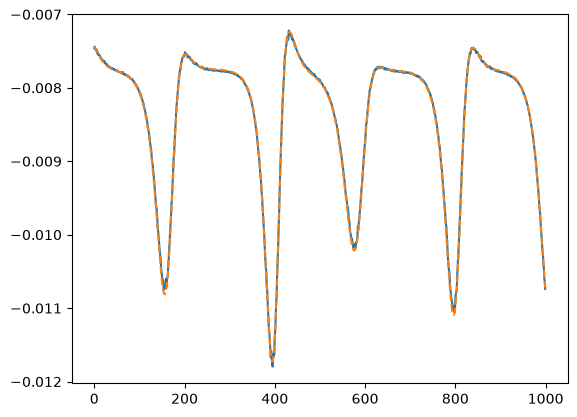

In [5]:
N_test = 100000
X_test = U_raw[0:3][:, idx_0+N_train:idx_0+N_train+N_test]
Y_test = U_raw[3:6][:, idx_0+N_train:idx_0+N_train+N_test]
Z_test = U_raw[6:9][:, idx_0+N_train:idx_0+N_train+N_test]

#X_test = torch.from_numpy(X_test)
Y_test = torch.from_numpy(Y_test)
#Z_test = torch.from_numpy(Z_test)

#X_test = (X_test - meanX[:, None]) / stdX[:, None]
#Z_test = (Z_test - meanZ[:, None]) / stdZ[:, None]

X_in_test = (Y_test - meanY[:, None]) / stdY[:, None]
X_in_test = X_in_test.t()
X_pred, Z_pred = cfm.sample(X_in_test)
X_pred = X_pred.t() * stdX[:, None] + meanX[:, None]
Z_pred = Z_pred.t() * stdZ[:, None] + meanZ[:, None]

import matplotlib.pyplot as plt
plt.plot(X_pred.numpy()[0,:][::100])
plt.plot(X_test[0,:][::100], '--')

In [6]:
import math
import torch

# Parámetros físicos del sistema L80
a1, a2, a3 = 1.0, 1.0, 3.0
v0 = 1.0 / 48.0
b1 = (a1 - a2 - a3) / 2.0
b2 = (a2 - a3 - a1) / 2.0
b3 = (a3 - a1 - a2) / 2.0
c = math.sqrt(b1 * b2 + b2 * b3 + b3 * b1)

def dYdt(x, y, z):
    x1, x2, x3 = x[..., 0], x[..., 1], x[..., 2]
    y1, y2, y3 = y[..., 0], y[..., 1], y[..., 2]
    z1, z2, z3 = z[..., 0], z[..., 1], z[..., 2]

    dy1dt = (- a3 * b3 * x2 * y3 - a2 * b2 * y2 * x3 + c * (a3 - a2) * y2 * y3 - a1 * x1 - v0 * a1**2 * y1) / a1
    dy2dt = (- a1 * b1 * x3 * y1 - a3 * b3 * y3 * x1 + c * (a1 - a3) * y3 * y1 - a2 * x2 - v0 * a2**2 * y2) / a2
    dy3dt = (- a2 * b2 * x1 * y2 - a1 * b1 * y1 * x2 + c * (a2 - a1) * y1 * y2 - a3 * x3 - v0 * a3**2 * y3) / a3

    return torch.stack([dy1dt, dy2dt, dy3dt], dim=-1)

def rk4_step_y(y, x, z, dt=4.2e-3):
    k1 = dYdt(x, y, z)
    k2 = dYdt(x, y + 0.5 * dt * k1, z)
    k3 = dYdt(x, y + 0.5 * dt * k2, z)
    k4 = dYdt(x, y + dt * k3, z)
    return y + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

In [7]:
N_test = 1500
X_test = U_raw[0:3][:, idx_0+N_train:idx_0+N_train+N_test]
Y_test = U_raw[3:6][:, idx_0+N_train:idx_0+N_train+N_test]
Z_test = U_raw[6:9][:, idx_0+N_train:idx_0+N_train+N_test]

N_ens = 50
Y0 = torch.from_numpy(Y_test[:,0])[:, None]
Y_pred = Y0 + 1e-5 * torch.randn((3,N_ens))

X_sim = []
for k in range(N_test):
    X_in_test = ( (Y_pred - meanY[:, None]) / stdY[:, None] ).t()
    
    X_out_test = cfm.sample(X_in_test)
    X_pred, Z_pred = X_out_test
    
    X_pred = X_pred.t() * stdX[:, None] + meanX[:, None]
    Z_pred = Z_pred.t() * stdZ[:, None] + meanZ[:, None]
    
    Y_pred = rk4_step_y(Y_pred.t(), X_pred.t(), Z_pred.t()).t()

    X_sim.append(torch.hstack([X_pred.mean(dim=-1), Y_pred.mean(dim=-1), Z_pred.mean(dim=-1)]))

    if k % 100 == 0:
        print(f"PROGRESS: {k} / {N_test}")
        
X_sim = torch.stack(X_sim)

PROGRESS: 0 / 1500
PROGRESS: 100 / 1500
PROGRESS: 200 / 1500
PROGRESS: 300 / 1500
PROGRESS: 400 / 1500
PROGRESS: 500 / 1500
PROGRESS: 600 / 1500
PROGRESS: 700 / 1500
PROGRESS: 800 / 1500
PROGRESS: 900 / 1500
PROGRESS: 1000 / 1500
PROGRESS: 1100 / 1500
PROGRESS: 1200 / 1500
PROGRESS: 1300 / 1500
PROGRESS: 1400 / 1500


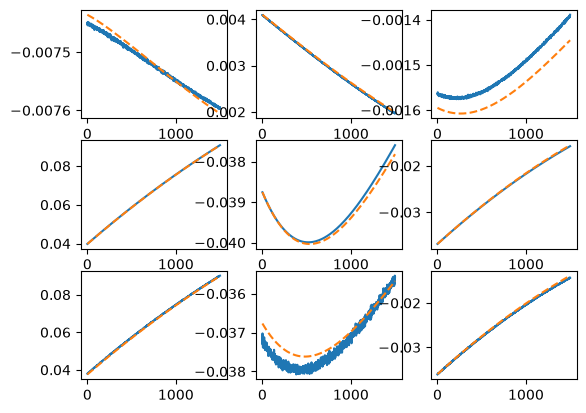

In [15]:
plt.subplot(3,3,1)
plt.plot(X_sim[:,0])
plt.plot(X_test[0], '--')
plt.subplot(3,3,2)
plt.plot(X_sim[:,1])
plt.plot(X_test[1], '--')
plt.subplot(3,3,3)
plt.plot(X_sim[:,2])
plt.plot(X_test[2], '--')

plt.subplot(3,3,4)
plt.plot(X_sim[:,3])
plt.plot(Y_test[0], '--')
plt.subplot(3,3,5)
plt.plot(X_sim[:,4])
plt.plot(Y_test[1], '--')
plt.subplot(3,3,6)
plt.plot(X_sim[:,5])
plt.plot(Y_test[2], '--')

plt.subplot(3,3,7)
plt.plot(X_sim[:,6])
plt.plot(Z_test[0], '--')
plt.subplot(3,3,8)
plt.plot(X_sim[:,7])
plt.plot(Z_test[1], '--')
plt.subplot(3,3,9)
plt.plot(X_sim[:,8])
plt.plot(Z_test[2], '--')